In [ ]:
"""
Duffing + Renormalización numérica (primer orden) + Caso lineal + Zoom
"""

import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt

# -------------------------
# Parámetros
# -------------------------
omega = 1.0
eps = 0.8
T = 200
N = 5001
rtol = 1e-9
atol = 1e-12

phi0_init = 1.0
pi0_init = 0.0

t = np.linspace(0.0, T, N)
dt = t[1] - t[0]

# -------------------------
# FUNCIONES DE INTEGRACIÓN
# -------------------------

def composite_simpson(y, x):
    """
    Simpson compuesto clásico.
    Requiere número par de intervalos => len(x) impar. (Tu N=5001 cumple)
    """
    n = len(x) - 1
    if n % 2 != 0:
        raise ValueError("Simpson compuesto requiere número par de intervalos.")
    h = (x[-1] - x[0]) / n
    S = y[0] + y[-1] + 4 * np.sum(y[1:-1:2]) + 2 * np.sum(y[2:-2:2])
    return S * h / 3.0


def gauss_legendre_integral(y_values, x_grid, n_nodes=64):
    """
    Cuadratura Gauss–Legendre de orden n_nodes.
    Usa interpolación cúbica para evaluar la función.
    """
    interp = interp1d(x_grid, y_values, kind='cubic', bounds_error=False, fill_value="extrapolate")
    nodes, weights = leggauss(n_nodes)

    a, b = x_grid[0], x_grid[-1]
    pts = 0.5*(b-a)*nodes + 0.5*(b+a)
    vals = interp(pts)

    return 0.5*(b-a)*np.dot(weights, vals)


def trapz_integral(y, x):
    """Wrapper para mantener nombres similares"""
    return np.trapz(y, x)



# -------------------------
# 1) Duffing completo
# -------------------------
def duffing_rhs(tt, y, omega, eps):
    phi, pi = y
    return [pi, -omega**2 * phi - eps * phi**3]

sol_full = solve_ivp(duffing_rhs, (t[0], t[-1]), [phi0_init, pi0_init],
                     args=(omega, eps), t_eval=t, method='RK45',
                     rtol=rtol, atol=atol)
phi_full = sol_full.y[0]
pi_full = sol_full.y[1]

# -------------------------
# 2) Fondo armónico
# -------------------------
phi_background = np.cos(omega * t)
pi_background  = -omega * np.sin(omega * t)

# -------------------------
# 3) Corrección 1er orden
# -------------------------
def first_order_rhs(tt, y, omega):
    phi1, pi1 = y
    idx = int(round((tt - t[0]) / dt))
    idx = max(0, min(len(t) - 1, idx))
    forcing = - (phi_background[idx])**3
    return [pi1, -omega**2 * phi1 + forcing]

sol_phi1 = solve_ivp(first_order_rhs, (t[0], t[-1]), [0.0, 0.0],
                     args=(omega,), t_eval=t, method='RK45',
                     rtol=rtol, atol=atol)

phi1 = sol_phi1.y[0]
pi1  = sol_phi1.y[1]

# -------------------------
# 4) Base de proyección
# -------------------------
dphi_dphi   = -np.sin(omega * t)
dphi_domega = -t * np.sin(omega * t)

dpi_dphi    = -omega * np.cos(omega * t)
dpi_domega  = -np.sin(omega * t) - omega * t * np.cos(omega * t)

# -------------------------
# 5) MATRIZ NORMAL usando cualquier método de integración
# -------------------------

# Cambiar AQUÍ el método que quieras usar:
#integrate = trapz_integral           # <= TRAPZ (rápido)
#integrate = composite_simpson      # <= SIMPSON (más preciso)
integrate = lambda y,x: gauss_legendre_integral(y,x,n_nodes=64)  # <= GAUSS (muy preciso)

M = np.zeros((2,2))
M[0,0] = integrate(dphi_dphi*dphi_dphi + dpi_dphi*dpi_dphi, t)
M[0,1] = integrate(dphi_dphi*dphi_domega + dpi_dphi*dpi_domega, t)
M[1,0] = M[0,1]
M[1,1] = integrate(dphi_domega*dphi_domega + dpi_domega*dpi_domega, t)

b = np.zeros(2)
b[0] = integrate(dphi_dphi*phi1 + dpi_dphi*pi1, t)
b[1] = integrate(dphi_domega*phi1 + dpi_domega*pi1, t)

# -------------------------
# Resolver sistema
# -------------------------
cond = np.linalg.cond(M)
if cond > 1e12:
    delta_lambda = np.linalg.pinv(M) @ b
else:
    delta_lambda = np.linalg.solve(M, b)

delta_phi   = delta_lambda[0]
delta_omega = delta_lambda[1]

print("Desplazamientos (orden ε^1):")
print("  Δϕ  = {:.6e}".format(delta_phi))
print("  Δω  = {:.6e}".format(delta_omega))

Desplazamientos (orden ε^1):
  Δϕ  = -7.223902e-04
  Δω  = 3.749409e-01


###Resultados


---


**trapz**

Δϕ  = 9.619525e-03

Δω  = 3.743423e-01


---



**Simpson**

  Δϕ  = 9.619573e-03

  Δω  = 3.743423e-01


---



**Gauss**

  Δϕ  = 9.619578e-03

  Δω  = 3.743423e-01


---




In [ ]:
# renorm reemplazar terminos hallados
omega_R = omega + eps * delta_omega
phase_shift = eps * delta_phi
phi_R = np.cos(omega_R * t + phase_shift)
pi_R = -omega_R * np.sin(omega_R * t + phase_shift)

In [ ]:
# -------------------------
# 7) Perturbativa ingenua
# -------------------------
phi_pert = phi_background + eps * phi1
pi_pert = pi_background + eps * pi1

# -------------------------
# 8) Lineal (ε=0)
# -------------------------
phi_lin = np.cos(omega * t)
pi_lin = -omega * np.sin(omega * t)

# -------------------------
# 9) Errores
# -------------------------
err_full = np.linalg.norm(phi_full - phi_R) / np.sqrt(len(t))
err_pert = np.linalg.norm(phi_full - phi_pert) / np.sqrt(len(t))
print("\nErrores RMS (φ):")
print("  Renormalizada vs Full : {:.3e}".format(err_full))
print("  Perturbativa vs Full  : {:.3e}".format(err_pert))



Errores RMS (φ):
  Renormalizada vs Full : 9.264e-01
  Perturbativa vs Full  : 2.458e+01


### ERRORES
---

**trapz**

Errores RMS (φ):

  Renormalizada vs Full : 7.057e-03

  Perturbativa vs Full  : 8.645e-02

---



**Simpson**

Errores RMS (φ):

  Renormalizada vs Full : 7.057e-03

  Perturbativa vs Full  : 8.645e-02


---



**Gauss**

Errores RMS (φ):

  Renormalizada vs Full : 7.057e-03
  
  Perturbativa vs Full  : 8.645e-02


---





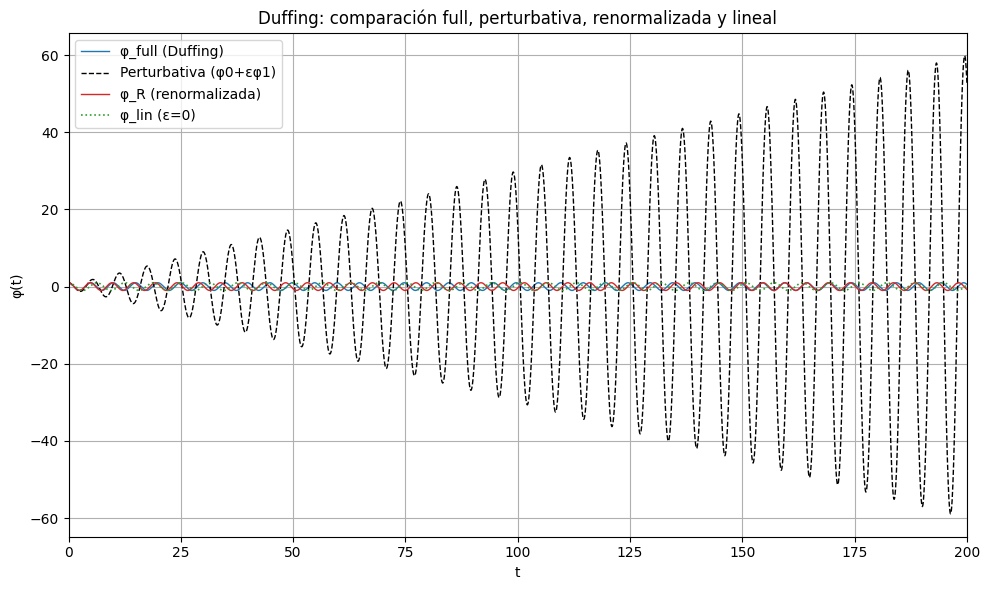

In [ ]:
# -------------------------
# 10) Gráficos
# -------------------------
plt.figure(figsize=(10,6))
plt.plot(t, phi_full, label='φ_full (Duffing)', color='C0', linewidth=1)
plt.plot(t, phi_pert, '--', label='Perturbativa (φ0+εφ1)', color='k', linewidth=1)
plt.plot(t, phi_R, label='φ_R (renormalizada)', color='C3', linewidth=1)
plt.plot(t, phi_lin, ':', label='φ_lin (ε=0)', color='C2', linewidth=1.2)
plt.xlim(0, min(200, T))
plt.xlabel('t')
plt.ylabel('φ(t)')
plt.title('Duffing: comparación full, perturbativa, renormalizada y lineal')
plt.legend()
plt.grid(True)
plt.tight_layout()

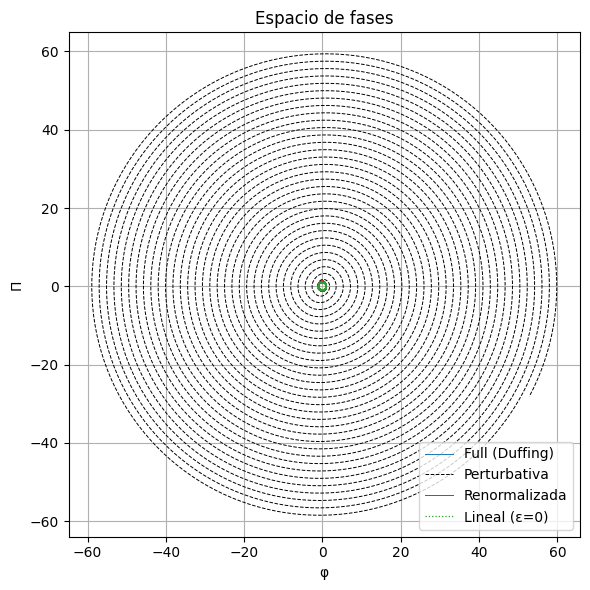

In [ ]:
plt.figure(figsize=(6,6))
plt.plot(phi_full, pi_full, label='Full (Duffing)', color='C0', linewidth=0.7)
plt.plot(phi_pert, pi_pert, '--', label='Perturbativa', color='k', linewidth=0.7)
plt.plot(phi_R, pi_R, label='Renormalizada', color='C3', linewidth=0.7)
plt.plot(phi_lin, pi_lin, ':', label='Lineal (ε=0)', color='C2', linewidth=0.9)
plt.xlabel('φ')
plt.ylabel('Π')
plt.title('Espacio de fases')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.tight_layout()

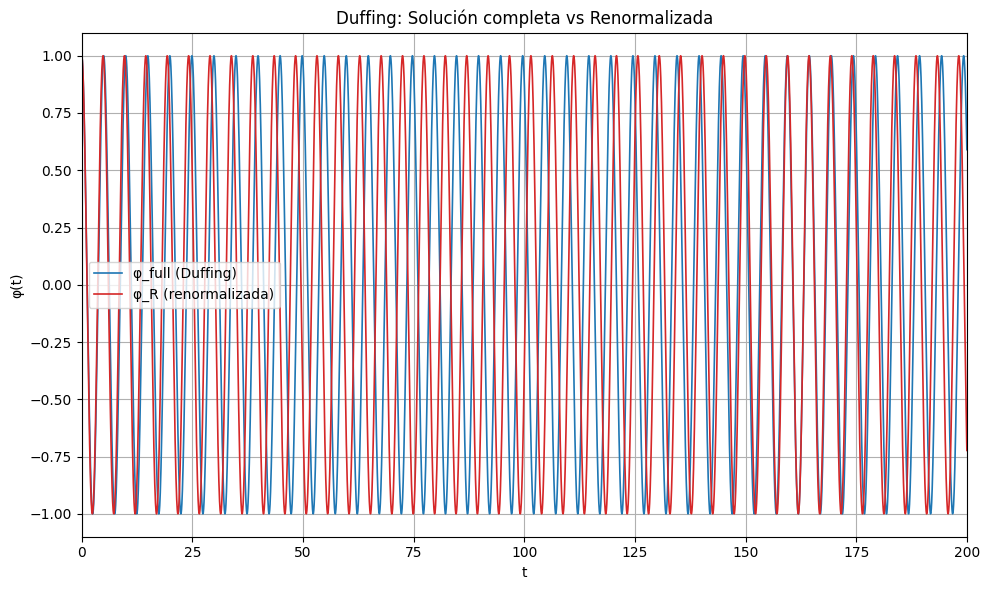

In [ ]:
# φ(t)
plt.figure(figsize=(10,6))
plt.plot(t, phi_full, label='φ_full (Duffing)', color='C0', linewidth=1.2)
plt.plot(t, phi_R, label='φ_R (renormalizada)', color='C3', linewidth=1.2)
plt.xlim(0, T)
plt.xlabel('t')
plt.ylabel('φ(t)')
plt.title('Duffing: Solución completa vs Renormalizada')
plt.legend()
plt.grid(True)
plt.tight_layout()

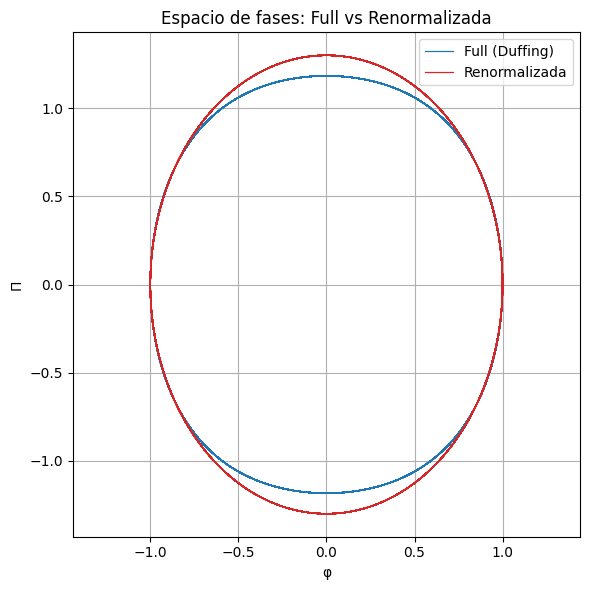

In [ ]:
# -------------------------

# -------------------------
# Gráficos: solo FULL vs RENORMALIZADA
# -------------------------


# Espacio de fases
plt.figure(figsize=(6,6))
plt.plot(phi_full, pi_full, label='Full (Duffing)', color='C0', linewidth=0.9)
plt.plot(phi_R, pi_R, label='Renormalizada', color='C3', linewidth=0.9)
plt.xlabel('φ')
plt.ylabel('Π')
plt.title('Espacio de fases: Full vs Renormalizada')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.tight_layout()

plt.show()

